# **Import Library**

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# **Load Dataset**

In [3]:
df = pd.read_csv("/content/hr_dataset_extended.csv")
df.head()

,Employee_ID,Join_Date,Department,Job_Role,Monthly_Salary,Overtime_Hours,Performance_Rating,Years_At_Company,Satisfaction_Level,Left_Company,Salary_Bracket,Resign_Risk
0,EMP001,2021-03-15,Engineering,Software Engineer,14500000,12,4,3,4,No,Senior,Safe
1,EMP002,2022-01-10,Marketing,Digital Marketer,8500000,8,3,2,3,No,Mid,Safe
2,EMP003,2020-05-20,Sales,Account Executive,11000000,25,2,4,2,Yes,Mid,High Risk
3,EMP004,2023-02-14,HR,HR Generalist,7500000,5,3,1,4,No,Mid,Safe
4,EMP005,2021-11-01,Finance,Financial Analyst,12000000,18,4,3,5,No,Mid,Safe


# **Cek dataset**

In [6]:
df.info()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Employee_ID         50 non-null     object
 1   Join_Date           50 non-null     object
 2   Department          50 non-null     object
 3   Job_Role            50 non-null     object
 4   Monthly_Salary      50 non-null     int64 
 5   Overtime_Hours      50 non-null     int64 
 6   Performance_Rating  50 non-null     int64 
 7   Years_At_Company    50 non-null     int64 
 8   Satisfaction_Level  50 non-null     int64 
 9   Left_Company        50 non-null     object
 10  Salary_Bracket      50 non-null     object
 11  Resign_Risk         50 non-null     object
dtypes: int64(5), object(7)
memory usage: 4.8+ KB


,0
Employee_ID,0
Join_Date,0
Department,0
Job_Role,0
Monthly_Salary,0
Overtime_Hours,0
Performance_Rating,0
Years_At_Company,0
Satisfaction_Level,0
Left_Company,0


## **Ubah Tipe Data Join_Date**

In [7]:
df["Join_Date"] = pd.to_datetime(df["Join_Date"])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Employee_ID         50 non-null     object        
 1   Join_Date           50 non-null     datetime64[ns]
 2   Department          50 non-null     object        
 3   Job_Role            50 non-null     object        
 4   Monthly_Salary      50 non-null     int64         
 5   Overtime_Hours      50 non-null     int64         
 6   Performance_Rating  50 non-null     int64         
 7   Years_At_Company    50 non-null     int64         
 8   Satisfaction_Level  50 non-null     int64         
 9   Left_Company        50 non-null     object        
 10  Salary_Bracket      50 non-null     object        
 11  Resign_Risk         50 non-null     object        
dtypes: datetime64[ns](1), int64(5), object(6)
memory usage: 4.8+ KB


# **Menambahkan Kolom Baru Total_Compansation**

In [8]:
df["Total_Compensation"] = df["Monthly_Salary"] * 1.10

df.head()

,Employee_ID,Join_Date,Department,Job_Role,Monthly_Salary,Overtime_Hours,Performance_Rating,Years_At_Company,Satisfaction_Level,Left_Company,Salary_Bracket,Resign_Risk,Total_Compensation
0,EMP001,2021-03-15,Engineering,Software Engineer,14500000,12,4,3,4,No,Senior,Safe,15950000.0
1,EMP002,2022-01-10,Marketing,Digital Marketer,8500000,8,3,2,3,No,Mid,Safe,9350000.0
2,EMP003,2020-05-20,Sales,Account Executive,11000000,25,2,4,2,Yes,Mid,High Risk,12100000.0
3,EMP004,2023-02-14,HR,HR Generalist,7500000,5,3,1,4,No,Mid,Safe,8250000.0
4,EMP005,2021-11-01,Finance,Financial Analyst,12000000,18,4,3,5,No,Mid,Safe,13200000.0


# **Mencari instigh**

In [10]:
df.groupby("Left_Company")["Satisfaction_Level"].mean()

,Satisfaction_Level
Left_Company,
No,3.6
Yes,1.9


Berdasarkan data diatas, dapat dilihat bahwa rata rata dari tingak kepuasan karyawan yang tidak resign adalah 3.6 yang artinya tingakt kepuasan karyawn lumayan bagus, sedangkan dri data tersebut dapat dilihat juga rata-rata tingakt kepuasan karyawan yang resign adalah 1.9 yang artinya sangat tidak puas. Maka dri itu daat disimpulkan tingat kepuasan karyawan sangat mempengaruhi karyawan akan resign atau tidak.

# **Membuat Visualisasi**

In [24]:
today = pd.Timestamp.now()

Tenure = (today- df['Join_Date']).dt.days / 365.25
df['Tenure'] = Tenure.astype(int)


df.head()

,Employee_ID,Join_Date,Department,Job_Role,Monthly_Salary,Overtime_Hours,Performance_Rating,Years_At_Company,Satisfaction_Level,Left_Company,Salary_Bracket,Resign_Risk,Total_Compensation,Tenure
0,EMP001,2021-03-15,Engineering,Software Engineer,14500000,12,4,3,4,No,Senior,Safe,15950000.0,5
1,EMP002,2022-01-10,Marketing,Digital Marketer,8500000,8,3,2,3,No,Mid,Safe,9350000.0,4
2,EMP003,2020-05-20,Sales,Account Executive,11000000,25,2,4,2,Yes,Mid,High Risk,12100000.0,6
3,EMP004,2023-02-14,HR,HR Generalist,7500000,5,3,1,4,No,Mid,Safe,8250000.0,3
4,EMP005,2021-11-01,Finance,Financial Analyst,12000000,18,4,3,5,No,Mid,Safe,13200000.0,4


/tmp/ipykernel_640/1520275831.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([left_yes, left_no], labels=["Yes", "No"])


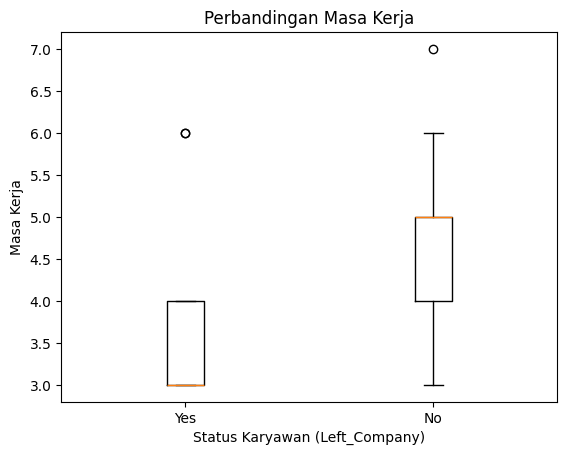

In [25]:
left_yes = df[df["Left_Company"] == "Yes"]["Tenure"]
left_no = df[df["Left_Company"] == "No"]["Tenure"]
plt.boxplot([left_yes, left_no], labels=["Yes", "No"])

plt.title("Perbandingan Masa Kerja")
plt.xlabel("Status Karyawan (Left_Company)")
plt.ylabel("Masa Kerja")
plt.show()

/tmp/ipykernel_640/1851967024.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([left_yes, left_no], labels=["Yes", "No"])


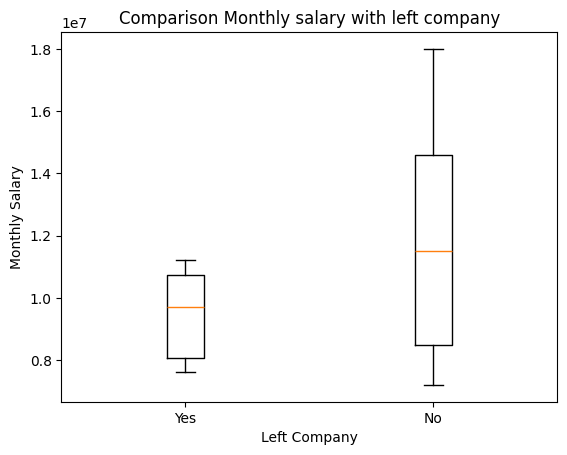

In [29]:
left_yes = df[df["Left_Company"] == "Yes"]["Monthly_Salary"]
left_no = df[df["Left_Company"] == "No"]["Monthly_Salary"]
plt.boxplot([left_yes, left_no], labels=["Yes", "No"])

plt.title("Comparison Monthly salary with left company")
plt.xlabel("Left Company")
plt.ylabel("Monthly Salary")
plt.show()

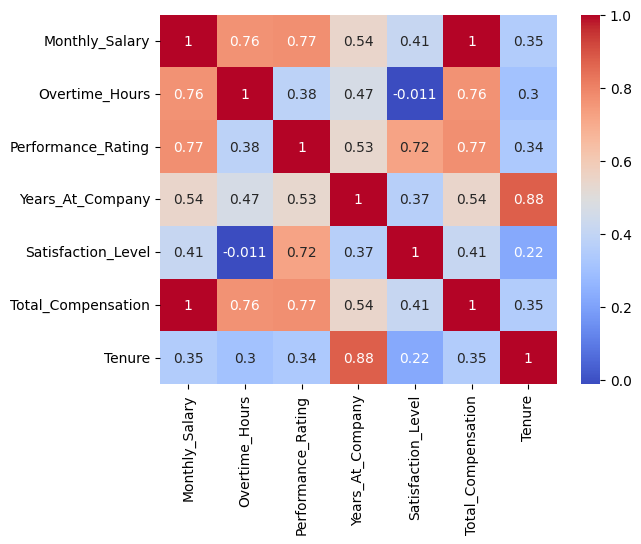

In [33]:
korelasi = df.corr(numeric_only=True)
sns.heatmap(korelasi, annot=True, cmap="coolwarm")
plt.show()